In [20]:
pip install ultralytics

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 836.9/836.9 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 MB 11.2 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [ultralytics] 4/5 [ultralytics]me-32]
Note: you may need to restart the kernel to use updated packages.


In [19]:
from ultralytics import YOLO
import os
import time
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [20]:
YOLOV10_MODEL = "yolov10n.pt"

YOLOV10_DATA = "/home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml"

YOLOV10_PROJECT = "/home/f15c/H/runs/detect/YOLO_Experiments"

YOLOV10_RUN_NAME = "YOLOv10n_Plastic_Shampoo_Bottle"

In [3]:
start_time = time.time()

model = YOLO(YOLOV10_MODEL)

results = model.train(
    data=YOLOV10_DATA,
    epochs=100,
    imgsz=640,
    batch=16,
    workers=4,
    device=0,
    project=YOLOV10_PROJECT,
    name=YOLOV10_RUN_NAME
)

end_time = time.time()

YOLOV10_TRAIN_TIME = (end_time - start_time) / 60

print(f"Training Time = {YOLOV10_TRAIN_TIME:.2f} min")

Ultralytics 8.4.73 🚀 Python-3.12.11 torch-2.8.0+cu129 CUDA:0 (NVIDIA GeForce RTX 2080 SUPER, 7783MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv10n_Plastic_Shampoo_Bottle, nbs=64, nms=False, opset=No

In [21]:
YOLOV10_RESULTS_DIR = os.path.join(
    YOLOV10_PROJECT,
    YOLOV10_RUN_NAME
)

print(YOLOV10_RESULTS_DIR)

/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv10n_Plastic_Shampoo_Bottle


In [22]:
import pandas as pd
results_csv = os.path.join(
    YOLOV10_RESULTS_DIR,
    "results.csv"
)

yolov10_results = pd.read_csv(results_csv)

yolov10_results.head()

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,61.0039,2.20921,4.85142,1.26603,0.44970,0.32031,0.29952,0.12190,1.86458,3.99039,1.21110,0.000237,0.000237,0.000237
1,2,111.5190,1.99612,3.11501,1.18786,0.38018,0.40627,0.37217,0.15090,1.88084,3.02218,1.23156,0.000471,0.000471,0.000471
2,3,160.8190,1.98716,2.40942,1.21313,0.47536,0.52343,0.44405,0.18249,1.90383,2.32402,1.24514,0.000699,0.000699,0.000699
3,4,210.0930,1.99426,2.02906,1.22507,0.53348,0.59108,0.55801,0.22823,1.88113,1.80355,1.23885,0.000693,0.000693,0.000693
4,5,258.4990,1.96536,1.83314,1.21751,0.52881,0.58970,0.54936,0.22915,1.90113,1.68752,1.25834,0.000686,0.000686,0.000686


In [23]:
final_epoch = yolov10_results.iloc[-1]

YOLOV10_PRECISION = final_epoch["metrics/precision(B)"]

YOLOV10_RECALL = final_epoch["metrics/recall(B)"]

YOLOV10_MAP50 = final_epoch["metrics/mAP50(B)"]

YOLOV10_MAP5095 = final_epoch["metrics/mAP50-95(B)"]

YOLOV10_F1 = (
    2 * YOLOV10_PRECISION * YOLOV10_RECALL
) / (
    YOLOV10_PRECISION + YOLOV10_RECALL + 1e-8
)

print("Precision =", YOLOV10_PRECISION)
print("Recall    =", YOLOV10_RECALL)
print("F1        =", YOLOV10_F1)
print("mAP50     =", YOLOV10_MAP50)
print("mAP50-95  =", YOLOV10_MAP5095)

Precision = 0.7538
Recall    = 0.8285
F1        = 0.7893867105518125
mAP50     = 0.8309
mAP50-95  = 0.41521


In [10]:
best_model = os.path.join(
    YOLOV10_RESULTS_DIR,
    "weights",
    "best.pt"
)

model = YOLO(best_model)

metrics = model.val(
    data=YOLOV10_DATA,
    split="val"
)

metrics

Ultralytics 8.4.73 🚀 Python-3.12.11 torch-2.8.0+cu129 CUDA:0 (NVIDIA GeForce RTX 2080 SUPER, 7783MiB)
YOLOv10n summary (fused): 102 layers, 2,267,118 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5.4±0.9 MB/s, size: 24.0 KB)
val: Scanning /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/valid/labels... 1582 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1582/1582 296.9it/s 5.3s0.0s
val: New cache created: /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 99/99 18.0it/s 5.5s0.0s
                   all       1582       5648      0.747      0.838      0.832      0.416
         adhesion_marg         80        140      0.632      0.721      0.726      0.327
        adhesion_unacc        128        299      0.915       0.98      0.988      0.725
             dent_marg        249        911      0.905      0.928      0.948      0.448


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bc5af20e090>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

In [24]:
import pandas as pd

df = pd.read_csv(
    "/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv10n_Plastic_Shampoo_Bottle/results.csv"
)

df.head()

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,61.0039,2.20921,4.85142,1.26603,0.44970,0.32031,0.29952,0.12190,1.86458,3.99039,1.21110,0.000237,0.000237,0.000237
1,2,111.5190,1.99612,3.11501,1.18786,0.38018,0.40627,0.37217,0.15090,1.88084,3.02218,1.23156,0.000471,0.000471,0.000471
2,3,160.8190,1.98716,2.40942,1.21313,0.47536,0.52343,0.44405,0.18249,1.90383,2.32402,1.24514,0.000699,0.000699,0.000699
3,4,210.0930,1.99426,2.02906,1.22507,0.53348,0.59108,0.55801,0.22823,1.88113,1.80355,1.23885,0.000693,0.000693,0.000693
4,5,258.4990,1.96536,1.83314,1.21751,0.52881,0.58970,0.54936,0.22915,1.90113,1.68752,1.25834,0.000686,0.000686,0.000686


In [25]:
%cd /home/f15c/H/runs/detect/YOLO_Experiments/YOLOv10n_Plastic_Shampoo_Bottle

/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv10n_Plastic_Shampoo_Bottle


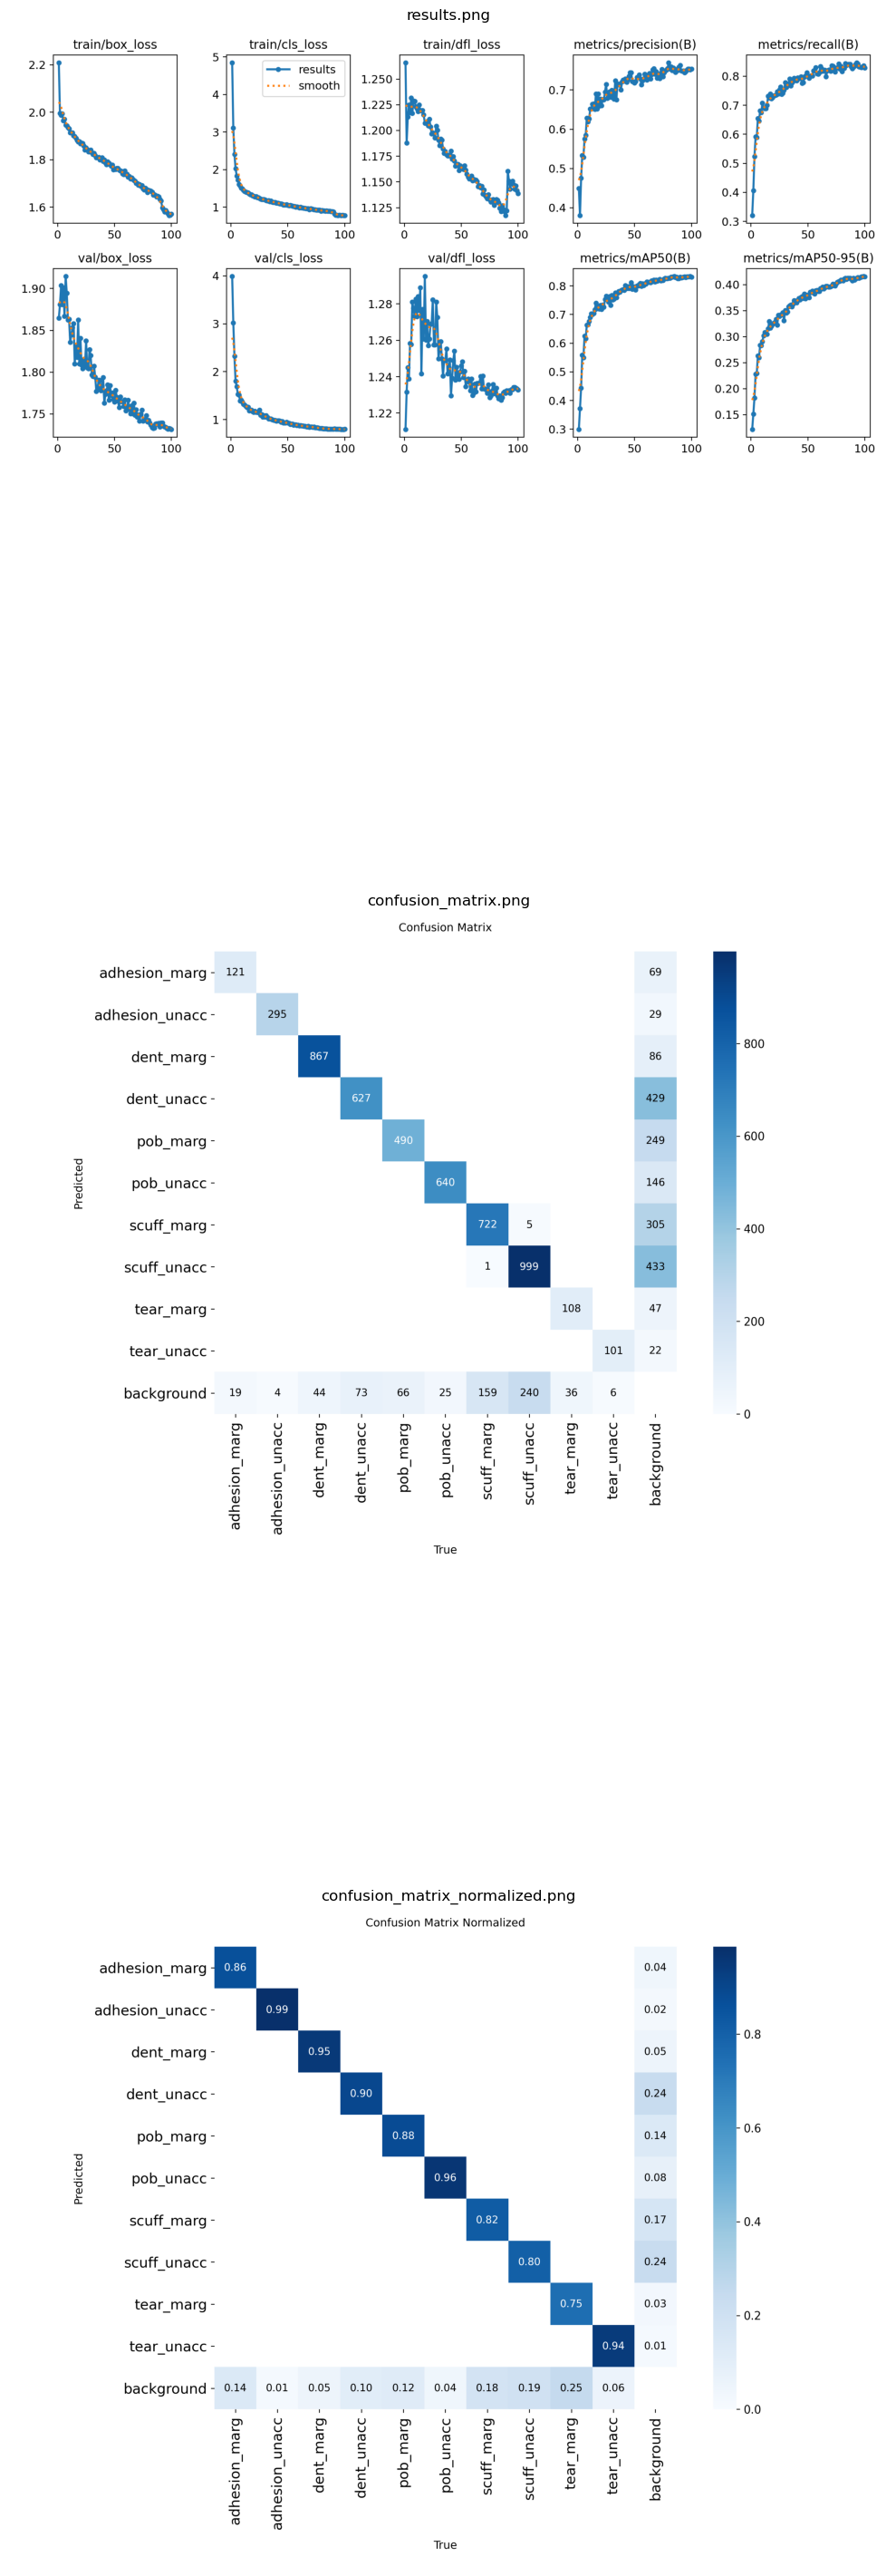

In [8]:
%matplotlib inline
plot_files = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
]

fig, axes = plt.subplots(
    len(plot_files),
    1,
    figsize=(10, 35)
)

for ax, plot in zip(axes, plot_files):

    img_path = os.path.join(
        YOLOV10_RESULTS_DIR,
        plot
    )

    if os.path.exists(img_path):

        img = Image.open(img_path)

        ax.imshow(img)

        ax.set_title(plot)

        ax.axis("off")

plt.tight_layout()
plt.show()

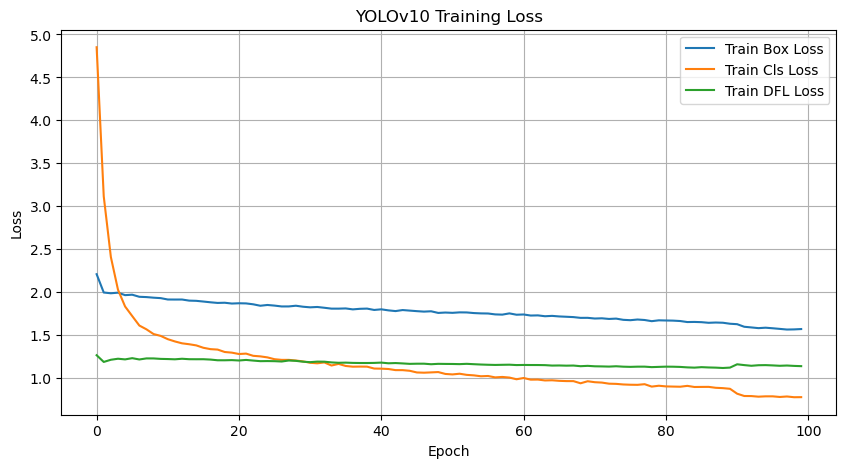

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(df["train/box_loss"], label="Train Box Loss")
plt.plot(df["train/cls_loss"], label="Train Cls Loss")
plt.plot(df["train/dfl_loss"], label="Train DFL Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLOv10 Training Loss")
plt.legend()
plt.grid()

plt.show()

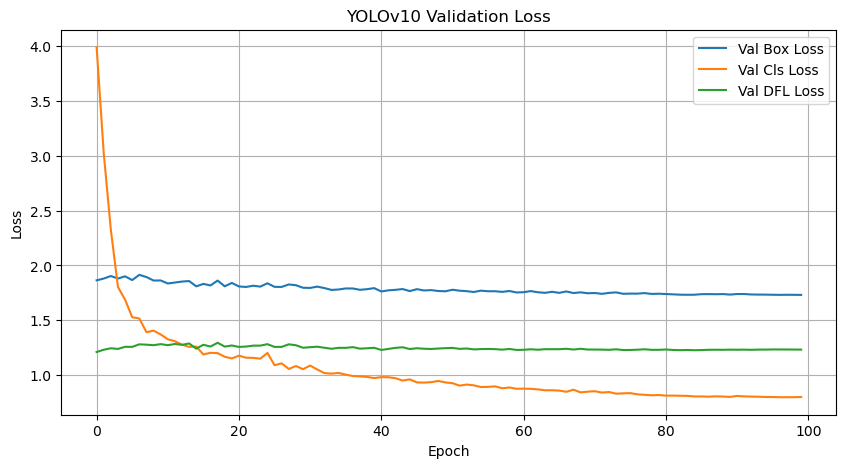

In [18]:
plt.figure(figsize=(10,5))

plt.plot(df["val/box_loss"], label="Val Box Loss")
plt.plot(df["val/cls_loss"], label="Val Cls Loss")
plt.plot(df["val/dfl_loss"], label="Val DFL Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLOv10 Validation Loss")
plt.legend()
plt.grid()

plt.show()

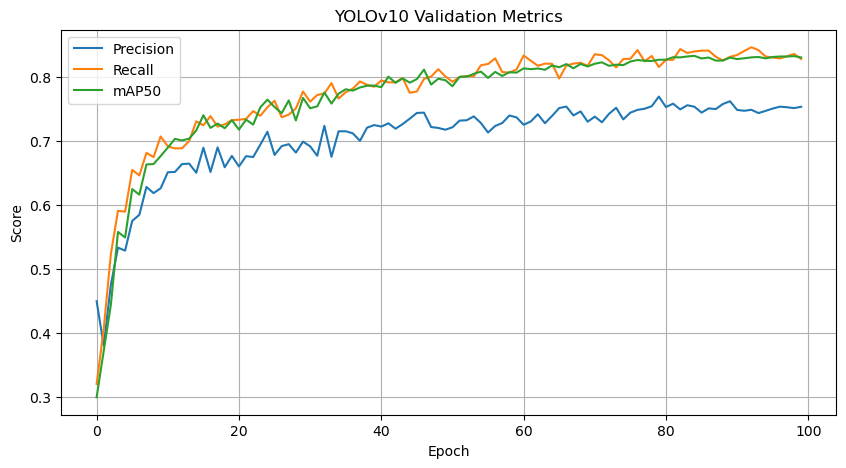

In [26]:
plt.figure(figsize=(10,5))

plt.plot(df["metrics/precision(B)"], label="Precision")
plt.plot(df["metrics/recall(B)"], label="Recall")
plt.plot(df["metrics/mAP50(B)"], label="mAP50")

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("YOLOv10 Validation Metrics")
plt.legend()
plt.grid()

plt.show()

In [34]:
YOLOV10_RESULTS = {
    "Model": "YOLOv10n",
    "Precision": YOLOV10_PRECISION,
    "Recall": YOLOV10_RECALL,
    "F1": YOLOV10_F1,
    "mAP50": YOLOV10_MAP50,
    "Training_Time_Min": "82.50 Minutes"
}

YOLOV10_RESULTS

{'Model': 'YOLOv10n',
 'Precision': 0.7538,
 'Recall': 0.8285,
 'F1': 0.7893867105518125,
 'mAP50': 0.8309,
 'Training_Time_Min': '82.50 Minutes'}

In [29]:
from ultralytics import YOLO

model = YOLO(
    "/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv10n_Plastic_Shampoo_Bottle/weights/best.pt"
)

test_metrics = model.val(
    data="/home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml",
    split="test",
    imgsz=640,
    plots=True
)

Ultralytics 8.4.76 🚀 Python-3.12.11 torch-2.8.0+cu129 CUDA:0 (NVIDIA GeForce RTX 2080 SUPER, 7783MiB)
YOLOv10n summary (fused): 102 layers, 2,267,118 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4.7±0.7 MB/s, size: 17.5 KB)
val: Scanning /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/test/labels.cache... 790 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 790/790 207.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 14.4it/s 3.5s0.1s
                   all        790       2920      0.763      0.838      0.844      0.432
         adhesion_marg         46         93      0.652      0.763      0.803      0.413
        adhesion_unacc         85        199      0.883      0.984      0.969      0.738
             dent_marg        106        387      0.904      0.923      0.945       0.43
            dent_unacc         99        315      0.623      0.881      0.752      0.305

In [30]:
print("Precision :", test_metrics.box.mp)
print("Recall    :", test_metrics.box.mr)
print("mAP50     :", test_metrics.box.map50)


Precision : 0.7625441002621952
Recall    : 0.8379661289103891
mAP50     : 0.8443977206017321


In [31]:
P = test_metrics.box.mp
R = test_metrics.box.mr

F1 = 2 * (P * R) / (P + R)

print("F1 Score:", F1)

F1 Score: 0.7984780305346801
